In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve

In [2]:
df_immunor = pd.read_csv("./example_viral_coded_ImmunoKade_score.csv",low_memory=False)
print(df_immunor.shape)
df_immunor.head()

(24409, 15)


,peptide,hla,label,MHC_Pep,BigMHC_EL,BigMHC_IM,MUNIS,NetMHCpan4.1b_EL,pept_len,pept_code_left,pept_code_right,hla_peptide_pocket,ImmunoKade_BA,ImmunoKade_EL,ImmunoKade_IM
0,KLEDLERDL,A0201,1,A0201_KLEDLERDL,0.047625,0.174026,0.760254,0.1344,9,KLEDLERDLXXXXXX,XXXXXXKLEDLERDL,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,0.446296,0.558487,0.292240
1,FLFLRNFSL,A0201,1,A0201_FLFLRNFSL,0.828803,0.350934,0.906250,0.8959,9,FLFLRNFSLXXXXXX,XXXXXXFLFLRNFSL,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,0.574008,0.805330,0.398036
2,FPPSPLFFFL,A0201,1,A0201_FPPSPLFFFL,0.004410,0.055259,0.065186,0.0015,10,FPPSPLFFFLXXXXX,XXXXXFPPSPLFFFL,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,0.356697,0.266402,0.211175
3,FLPSPLFFFL,A0201,1,A0201_FLPSPLFFFL,0.050787,0.146385,0.372559,0.3991,10,FLPSPLFFFLXXXXX,XXXXXFLPSPLFFFL,YFAMYGEKVAHTHVDTLYVRYHYYTWAVLAYTWY,0.472033,0.571066,0.313125
4,YTDFVGEGL,C0501,1,C0501_YTDFVGEGL,0.761308,0.215918,0.980469,0.8824,9,YTDFVGEGLXXXXXX,XXXXXXYTDFVGEGL,YYAGYREKYRQTDVNKLYLRYNFYTWAERAYTWY,0.583058,0.864546,0.361519


# Performance plots

In [3]:
dict_models_color = {
    "NetMHCpan4.1b_EL":"gold",
    "MUNIS":"green",
    "BigMHC_EL":"deepskyblue",
    "BigMHC_IM":"blue",
    "ImmunoKade_EL":"darkorange",
    "ImmunoKade_IM":"red",
}

models_name = list(dict_models_color.keys())

In [4]:
def get_metrics_roc(y_bin, y_score):
    fpr, tpr, _ = roc_curve(y_bin, y_score)
    roc_auc = auc(fpr, tpr)
    return (fpr, tpr, roc_auc)

def get_metrics_pr(y_bin, y_score):
    precision, recall, _ = precision_recall_curve(y_bin, y_score)
    pr_auc = auc(recall, precision)
    return (precision, recall, pr_auc)

def get_PPVn_fast(y_bin, y_score, n=None):
    y_bin = np.asarray(y_bin)
    y_score = np.asarray(y_score)

    sorted_idx = np.argsort(y_score)[::-1]
    y_bin_sorted = y_bin[sorted_idx]

    if n is None:
        n = int(y_bin.sum())
    
    # cumsum dei veri positivi
    tp_cum = np.cumsum(y_bin_sorted)

    # i = 1, 2, ..., n-1
    i = np.arange(1, n)

    PPVn = tp_cum[:n-1] / i
    mean = PPVn.mean()

    return i.tolist(), PPVn.tolist(), mean

Test shape: 24409
Negative length: 20777
Positive length: 3632
Pos/Tot: 0.149


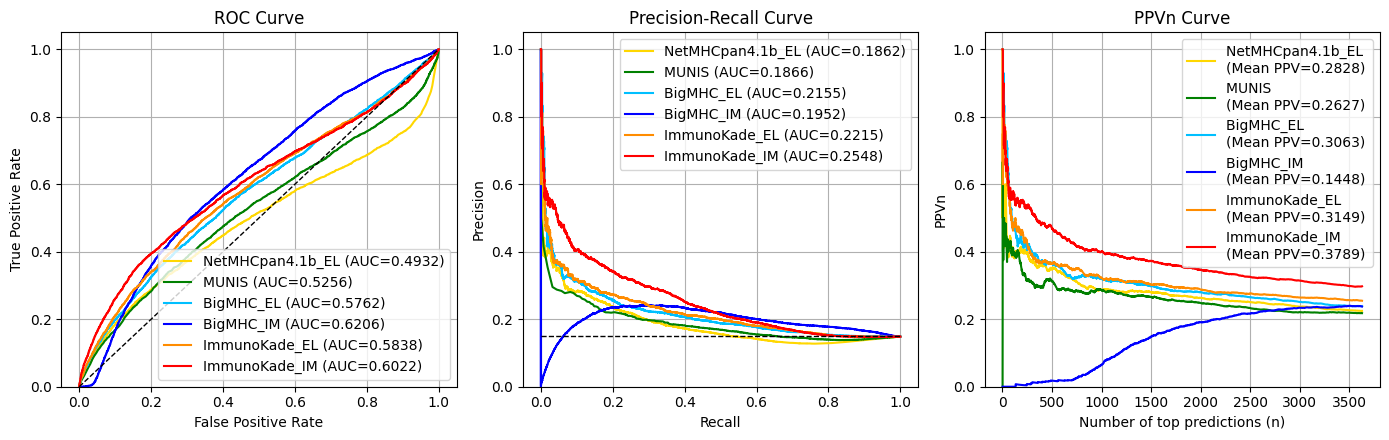

In [5]:
df_perfomance = df_immunor.copy()

df_perfomance = df_perfomance[models_name+["label"]]
df_perfomance = df_perfomance.dropna()

y_bin = df_perfomance["label"]

print("Test shape:",df_perfomance.shape[0])
print("Negative length:",y_bin.shape[0]-y_bin.sum())
print("Positive length:",y_bin.sum())
fraction = np.round(y_bin.sum()/y_bin.shape[0],3)
print("Pos/Tot:",fraction)

# Figure
fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))

# --- ROC Curve ---
for model in models_name:
    y_score = df_perfomance[model]
    fpr, tpr, roc_auc = get_metrics_roc(y_bin, y_score)
    axs[0].plot(fpr, tpr, color=dict_models_color[model],label='{} (AUC={:.4})'.format(model,roc_auc))
axs[0].plot([0, 1], [0, 1], 'k--', lw=1)
#axs[0].set_xlim([-0.05, 1.0])
axs[0].set_ylim([0.0, 1.05])
axs[0].set_xlabel('False Positive Rate')
axs[0].set_ylabel('True Positive Rate')
axs[0].set_title('ROC Curve')
axs[0].legend(loc="lower right")
axs[0].grid(True)

# --- Precision-Recall Curve ---
for model in models_name:
    y_score = df_perfomance[model]
    precision, recall, pr_auc = get_metrics_pr(y_bin, y_score)
    axs[1].plot(recall, precision, color=dict_models_color[model],label='{} (AUC={:.4})'.format(model,pr_auc))
axs[1].plot([0, 1], [fraction, fraction], 'k--', lw=1)
axs[1].set_ylim([0.0, 1.05])
axs[1].set_xlabel('Recall')
axs[1].set_ylabel('Precision')
axs[1].set_title('Precision-Recall Curve')
axs[1].legend(loc="best")
axs[1].grid(True)

# --- PPVn Curve ---
n=None
#n=1000
for model in models_name:
    y_score = df_perfomance[model]
    x, PPVn, mean = get_PPVn_fast(y_bin, y_score, n)
    axs[2].plot(x, PPVn, color=dict_models_color[model],label='{} \n(Mean PPV={:.4})'.format(model,mean))
axs[2].set_ylim([0.0, 1.05])
axs[2].set_xlabel('Number of top predictions (n)')
axs[2].set_ylabel('PPVn')
axs[2].set_title('PPVn Curve')
axs[2].legend(loc="best")
axs[2].grid(True)

# Show the plot
plt.tight_layout()
plt.show()
